# Airplane detector - a guided tour

This notebook walks through the detector one idea at a time, using the released model
(`models/airplane_fcn.keras`). Run `airdet download` first; everything else is already in the repo.

1. the data and why object size matters
2. what the network sees: one 40x40 window, one answer
3. one forward pass = every sliding window
4. the image pyramid: finding objects of any size
5. from thousands of candidates to a few boxes (NMS)
6. scoring the result on the held-out test split

In [1]:
import os
os.chdir("..") if os.path.basename(os.getcwd()) == "notebooks" else None
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import cv2
import matplotlib.pyplot as plt
import numpy as np

from airplane_detector import evaluate as ev
from airplane_detector.boxes import box_area
from airplane_detector.detect import Detector, prepare_level
from airplane_detector.sampling import PatchSampler, pyramid_scales
from airplane_detector.train import load_split_samples, run_detector, to_results
from airplane_detector.viz import draw_boxes, draw_evaluation, upscale

detector = Detector.load("models/airplane_fcn.keras")
cfg = detector.cfg
splits = load_split_samples(cfg)
print({name: (len(s), "images,", sum(len(x.boxes) for x in s), "airplanes") for name, s in splits.items()})

def show(img_bgr, title="", ax=None, size=5):
    ax = ax or plt.subplots(figsize=(size, size))[1]
    ax.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)); ax.set_title(title, fontsize=10); ax.axis("off")

{'train': (511, 'images,', 1877, 'airplanes'), 'val': (110, 'images,', 456, 'airplanes'), 'test': (110, 'images,', 560, 'airplanes')}


## 1. The data

733 aerial tiles (mostly 256x256) with axis-aligned airplane boxes. The split is **by image**, stratified by
how many airplanes an image contains, and stored in `data/splits.json` so every run sees the same test set.

Airplanes range from about 6 px to over 200 px. The first version of this project used a single 64x64 window,
which can only overlap an object with IoU >= 0.5 when that object is roughly 45-90 px wide.

median size 34 px;  25% of objects are 45-90 px


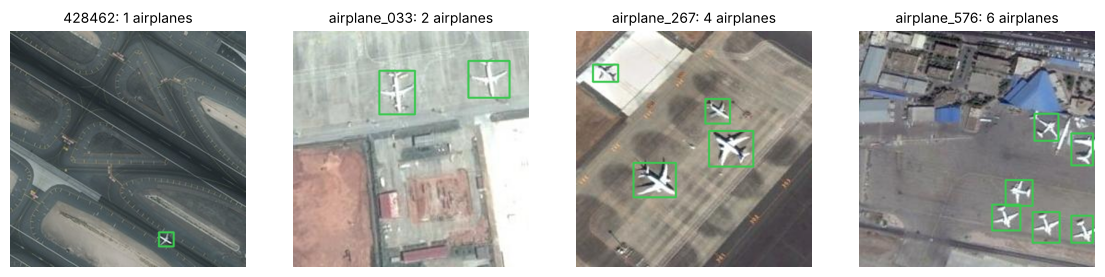

In [2]:
sizes = np.concatenate([np.sqrt(box_area(s.boxes)) for split in splits.values() for s in split if len(s.boxes)])
print(f"median size {np.median(sizes):.0f} px;  {np.mean((sizes >= 45) & (sizes <= 90)):.0%} of objects are 45-90 px")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, s in zip(axes, [splits["train"][i] for i in (3, 40, 200, 420)]):
    canvas, f = upscale(s.load(), 384)
    show(draw_boxes(canvas, s.boxes, factor=f), f"{s.name}: {len(s.boxes)} airplanes", ax)

## 2. What the network sees

The network has a 40x40 receptive field. In its centre sits a 24x24 **anchor** (cyan). A training patch is
*positive* when the anchor overlaps an airplane with IoU >= 0.5, and the network must also regress the
airplane's exact box (green) relative to the anchor. Negatives are random background, "near misses" (a plane
that is off-centre or at the wrong scale) and - after the first training stage - mined false positives.

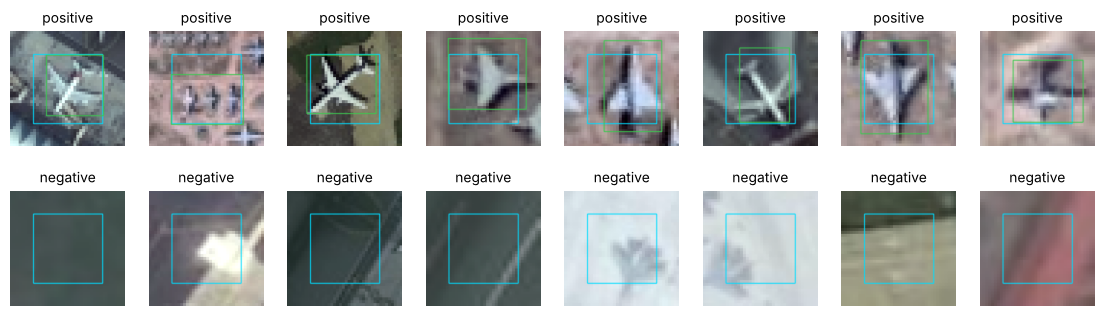

In [3]:
from airplane_detector.boxes import decode

sampler = PatchSampler(splits["train"][:60], cfg, augment=True)
x, y = sampler.sample_epoch(np.random.default_rng(0), pos_per_box=1)
anchor = np.array([[8, 8, 32, 32]], np.float32)
fig, axes = plt.subplots(2, 8, figsize=(14, 3.8))
for row, label in enumerate((1, 0)):
    for ax, i in zip(axes[row], np.flatnonzero(y[:, 0, 0, 0] == label)[:8]):
        patch = cv2.resize(x[i], (160, 160), interpolation=cv2.INTER_NEAREST)
        draw_boxes(patch, anchor, (255, 220, 0), thickness=1, factor=4)
        if label:
            draw_boxes(patch, decode(anchor, y[i, 0, 0, 1:][None]), (80, 200, 60), thickness=1, factor=4)
        show(patch, "positive" if label else "negative", ax)

## 3. One forward pass = every sliding window

All convolutions use `valid` padding, so the output for a 40x40 patch is a single 1x1 cell - and running the
same weights on a bigger image gives exactly the grid of answers a stride-8 sliding window would produce.
The original notebook called `model.predict` once per window (about 6 s per image); this does the same work
in one pass.

In [4]:
import time

sample = next(s for s in splits["test"] if 4 <= len(s.boxes) <= 8)
img = sample.load()
level, sx, sy = prepare_level(img, 1.0, cfg)

detector.forward(level)  # warm-up: the first call builds the TensorFlow graph
start = time.perf_counter()
dense = detector.forward(level)
dense_ms = (time.perf_counter() - start) * 1000

row, col = 11, 17
window = level[row * 8 : row * 8 + 40, col * 8 : col * 8 + 40]
single = detector.model(window[None].astype(np.float32), training=False).numpy()[0, 0, 0]
print(f"dense map {dense.shape[:2]} = {dense.shape[0] * dense.shape[1]} windows in {dense_ms:.0f} ms")
print("max |dense - single window| at one cell:", float(np.abs(dense[row, col] - single).max()))

dense map (32, 32) = 1024 windows in 22 ms
max |dense - single window| at one cell: 0.0


## 4. The image pyramid

A fixed 24 px anchor only matches ~24 px objects, so the image is resized to many scales
(3 per octave). At each level the network answers "is there an airplane of *this* size here?".
Below: the objectness map at four levels - small planes light up when the image is enlarged, large ones when
it is shrunk.

16 levels; object sizes matched: [8, 10, 13, 16, 20, 25, 32, 40, 51, 64, 81, 102, 128, 161, 203, 256] px


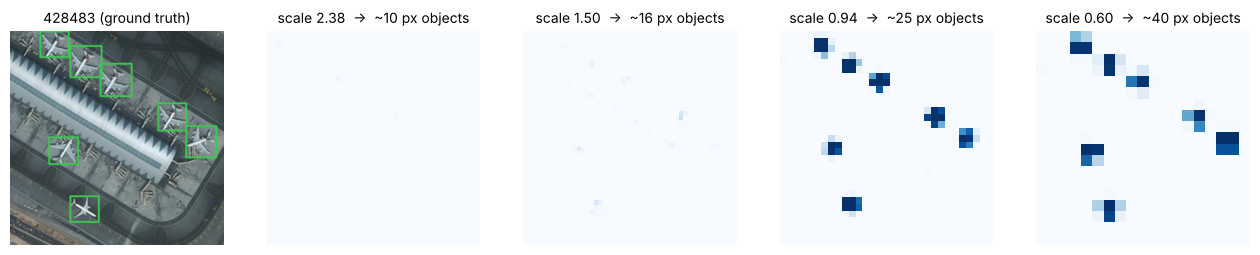

In [5]:
scales = pyramid_scales(cfg, *img.shape[:2])
print(len(scales), "levels; object sizes matched:", (cfg.anchor / scales).round(0).astype(int).tolist(), "px")

fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
canvas, f = upscale(img, 384)
show(draw_boxes(canvas, sample.boxes, factor=f), f"{sample.name} (ground truth)", axes[0])
for ax, scale in zip(axes[1:], scales[[1, 3, 5, 7]]):
    lvl, _, _ = prepare_level(img, float(scale), cfg)
    prob = 1 / (1 + np.exp(-detector.forward(lvl)[..., 0]))
    ax.imshow(prob, vmin=0, vmax=1, cmap="Blues"); ax.axis("off")
    ax.set_title(f"scale {scale:.2f}  ->  ~{cfg.anchor / scale:.0f} px objects", fontsize=10)

## 5. From candidates to boxes

Every cell above the score floor becomes a candidate box (anchor + regressed offsets, mapped back to image
pixels). Neighbouring cells and neighbouring pyramid levels all fire on the same airplane, so non-maximum
suppression keeps the best box of each cluster and *box voting* replaces it with the score-weighted average
of the boxes it suppressed. The score threshold is the one that maximised F1 on the
*validation* split.

87 candidates above 0.80  ->  7 after NMS (IoU 0.3);  ground truth: 7


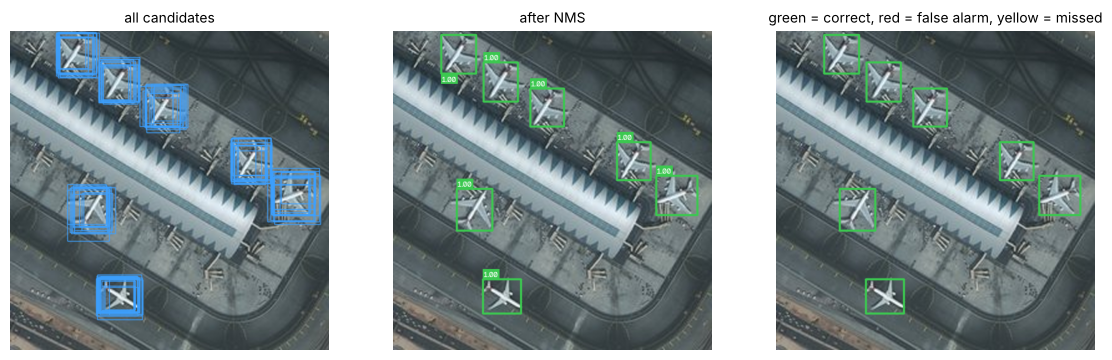

In [6]:
cand = detector.candidates(img, score_floor=cfg.score_threshold)
final = detector.merge(cand)  # NMS, then score-weighted box voting
print(f"{len(cand)} candidates above {cfg.score_threshold:.2f}  ->  {len(final)} after NMS (IoU {cfg.nms_iou});  ground truth: {len(sample.boxes)}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
canvas, f = upscale(img, 512)
show(draw_boxes(canvas.copy(), cand.boxes, (255, 160, 60), thickness=1, factor=f), "all candidates", axes[0])
show(draw_boxes(canvas.copy(), final.boxes, scores=final.scores, factor=f), "after NMS", axes[1])
show(draw_evaluation(img, sample.boxes, final.boxes), "green = correct, red = false alarm, yellow = missed", axes[2])

## 6. Scoring on the test split

Detections are matched to ground truth greedily by score (IoU >= 0.5, one detection per object), pooled over
all test images. AP is the COCO 101-point average precision; the implementation in `evaluate.py` is checked
against `pycocotools` in the test suite.

test images 110, airplanes 560
AP50 0.940  (95% CI 0.917-0.975)   AP75 0.429   mAP 0.486
at score >= 0.80:  precision 0.859  recall 0.921  F1 0.889


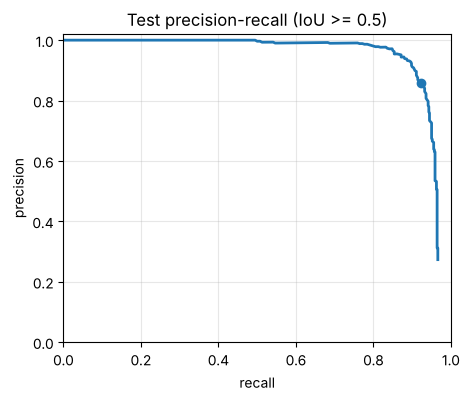

In [7]:
detections = run_detector(detector, splits["test"], progress=False)
report = ev.evaluate(to_results(splits["test"], detections), threshold=cfg.score_threshold)
op = report["operating_point"]
print(f"test images {report['images']}, airplanes {report['objects']}")
print(f"AP50 {report['AP50']:.3f}  (95% CI {report['AP50_ci95'][0]:.3f}-{report['AP50_ci95'][1]:.3f})   AP75 {report['AP75']:.3f}   mAP {report['mAP']:.3f}")
print(f"at score >= {op['threshold']:.2f}:  precision {op['precision']:.3f}  recall {op['recall']:.3f}  F1 {op['f1']:.3f}")

curve = report["pr_curve"]
plt.figure(figsize=(5, 4)); plt.plot(curve["recall"], curve["precision"], lw=2)
plt.scatter([op["recall"]], [op["precision"]], zorder=3)
plt.xlabel("recall"); plt.ylabel("precision"); plt.xlim(0, 1); plt.ylim(0, 1.02); plt.grid(alpha=.3)
plt.title("Test precision-recall (IoU >= 0.5)");